# Практичне завдання 3
## Дослідження ефективності TF-IDF зважених ембеддінгів для детекції текстів, згенерованих великими мовними моделями

**Мета:** перевірити гіпотезу, що зважування FastText-векторів слів за TF-IDF (виділення рідкісних, специфічних для ШІ термінів) дає кращу лінійну роздільність класів «людина / ШІ», ніж проста усереднена агрегація (Mean Pooling).


### Імпорт бібліотек та базові налаштування

- **`numpy`, `pandas`** — робота з масивами та таблицями (датасет, вектори документів);
- **`matplotlib`, `seaborn`** — графіки (гістограми, t-SNE, матриці помилок);
- **`spacy`** — лінгвістична обробка тексту (лематизація, стоп-слова);
- **`gensim.models.FastText`** — навчання ембеддингів слів із підслівною (subword) інформацією;
- **`sklearn`** — TF-IDF, розбиття вибірки, класифікатори (SVM, Logistic Regression, KNN), метрики, t-SNE;
- **`silhouette_score`** — число, що показує, наскільки добре кластери відокремлені один від одного (використаємо для кількісної оцінки геометрії).

`np.random.seed(42)` фіксує генератор випадкових чисел, щоб результати були відтворюваними. `warnings.filterwarnings('ignore')` лише ховає другорядні попередження, щоб вони не засмічували вивід.

In [18]:
import warnings, re, time
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from gensim.models import FastText
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score)

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
print('Бібліотеки імпортовано')

Бібліотеки імпортовано


## Етап 1. Завантаження та первинний аналіз даних

Завантажуємо датасет, перевіряємо структуру, баланс класів, розподіл довжин текстів та наявність артефактів (дублікати, порожні рядки, надто короткі тексти).

### 1.1 Завантаження даних та структура таблиці

Нас цікавлять головним чином стовпці: **`text_content`** (сам текст), **`label`** (клас: `human` або `ai`), **`source_model`** (яка модель згенерувала текст), **`domain`** (жанр: social / academic / news) та **`topic_hint`** (тема).

In [19]:
df = pd.read_csv('ai_vs_human_text_2026.csv')
print('Розмір датасету:', df.shape)
df.info()
display(df.head(3))

Розмір датасету: (2000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   object 
 1   label                2000 non-null   object 
 2   source_model         2000 non-null   object 
 3   domain               2000 non-null   object 
 4   text_content         2000 non-null   object 
 5   topic_hint           2000 non-null   object 
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   object 
dtypes: float64(1), int64(1), object(7)
memory usage: 140.8+ KB


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation


**Опис результату.** Датасет має **2000 рядків і 9 стовпців**. `info()` показує, що в усіх стовпцях по 2000 непорожніх значень, тобто **пропусків немає**. Типи: 7 текстових стовпців, один цілочисельний (`word_count`) і один дійсний (`avg_sentence_length`). У прикладі рядків видно, що тексти короткі (20–40 слів): це або розмовні соціальні дописи («can we talk about gene editing ethics…»), або формальні новинні/академічні формулювання, які пише модель (`gemini-2.0` у третьому рядку). Тобто класи відрізняються стилем.

### 1.2 Баланс класів та склад датасету

Перед навчанням потрібно перевірити, наскільки **збалансовані класи**: якщо одного класу набагато більше, звичайна точність (Accuracy) може вводити в оману, бо модель, що завжди відповідає «людина», вже матиме високу точність.

Клітинка виводить:
1. кількість текстів кожного класу (`value_counts`);
2. таблицю «джерело × мітка» (`pd.crosstab`) — щоб побачити, які саме моделі генерували ШІ-тексти;
3. таблицю «домен × мітка» — чи не залежить клас від жанру;
4. два стовпчикові графіки: баланс класів (ліворуч) та розподіл за доменами (праворуч).

Розподіл міток:
label
human    1334
ai        666
Name: count, dtype: int64

Джерело (source_model) × мітка:
label          ai  human
source_model            
gemini-2.0    333      0
gpt-4o        333      0
human           0   1334

Домен × мітка:
label      ai  human
domain              
academic  222    447
news      222    435
social    222    452


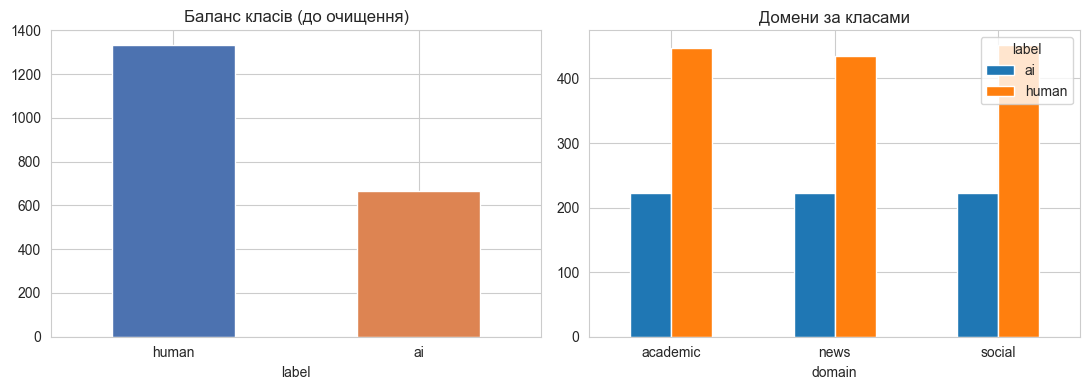

In [20]:
# Розподіл міток та джерел
print('Розподіл міток:')
print(df['label'].value_counts())
print('\nДжерело (source_model) × мітка:')
print(pd.crosstab(df['source_model'], df['label']))
print('\nДомен × мітка:')
print(pd.crosstab(df['domain'], df['label']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df['label'].value_counts().plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452'], rot=0)
ax[0].set_title('Баланс класів (до очищення)')
pd.crosstab(df['domain'], df['label']).plot.bar(ax=ax[1], rot=0)
ax[1].set_title('Домени за класами')
plt.tight_layout(); plt.show()

**Опис результату.** *Таблиці:* у датасеті **1334 людських** та **666 ШІ-текстів** (співвідношення 2 : 1). ШІ-тексти порівну згенеровані двома моделями: `gemini-2.0` (333) та `gpt-4o` (333). За доменами ШІ-тексти розподілені **рівномірно** (по 222 у academic, news та social), а людських текстів трохи більше в кожному домені (447 / 435 / 452). Отже, домен **не** виступає «підказкою» для класифікатора, бо у всіх жанрах частка ШІ приблизно однакова.

*Графіки:* лівий стовпчиковий графік наочно показує дисбаланс (синій стовпчик «human» удвічі вищий за помаранчевий «ai»). Правий графік показує, що всі три домени майже однакові за складом класів. Через дисбаланс далі ми спираємось на **macro-F1** та **Balanced Accuracy**.

### 1.3 Пошук артефактів: пропуски, порожні рядки, короткі тексти, дублікати

Реальні (і синтетичні) датасети часто містять «сміття», яке спотворює результати. Тут ми послідовно перевіряємо:

- **пропуски** (`isna`) — відсутні значення;
- **порожні тексти** — рядки, що складаються лише з пробілів;
- **надто короткі тексти** (< 10 слів) — з них важко отримати змістовний вектор;
- **повні дублікати** `text_content` (`duplicated`) — найнебезпечніший артефакт, бо однаковий текст може потрапити і в train, і в test, і тоді модель просто «впізнає» його, а метрика буде нереально високою (так званий **витік даних**, data leakage);
- **суперечливі мітки** — один і той самий текст із різними класами (група за `text_content` із більш ніж однією унікальною міткою).

Також рахуємо кількість слів `n_words` (розбиваємо текст по пробілах) та виводимо описову статистику (середнє, σ, мінімум, квартилі, максимум) по кожному класу.

In [21]:
# Пошук артефактів
print('Пропуски:\n', df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else 'відсутні')
print('Порожні тексти:', (df['text_content'].str.strip() == '').sum())
df['n_words'] = df['text_content'].str.split().str.len()
print('Тексти < 10 слів:', (df['n_words'] < 10).sum())
n_dup = df.duplicated('text_content').sum()
print(f'Повних дублікатів text_content: {n_dup} із {len(df)} ({n_dup/len(df):.1%})')
print('Унікальних текстів:', df['text_content'].nunique())
conflict = (df.groupby('text_content')['label'].nunique() > 1).sum()
print('Текстів з суперечливими мітками:', conflict)
print('\nСтатистика кількості слів:')
display(df.groupby('label')['n_words'].describe())

Пропуски:
 відсутні
Порожні тексти: 0
Тексти < 10 слів: 0
Повних дублікатів text_content: 1034 із 2000 (51.7%)
Унікальних текстів: 966
Текстів з суперечливими мітками: 0

Статистика кількості слів:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ai,666.0,38.004505,7.007513,23.0,35.0,39.0,44.0,50.0
human,1334.0,36.508246,9.662008,19.0,27.0,36.0,46.0,52.0


**Опис результату.** Пропусків, порожніх та надто коротких текстів **немає** (найкоротший текст — 19 слів). Проте знайдено **1034 повні дублікати** (51.7% датасету); унікальних текстів лише **966**. Суперечливих міток немає: однакові тексти завжди мають однаковий клас, тож дублікати можна безпечно видалити.

*Таблиця довжин:* ШІ-тексти — середнє 38.0 слова, σ = 7.0, діапазон 23–50, медіана 39; людські — середнє 36.5, σ = 9.7, діапазон 19–52, медіана 36. Тобто середні довжини майже однакові, але **людські тексти більш різноманітні за довжиною** (більший розкид), а ШІ-тексти «рівніші».

### 1.4 Розподіл довжини текстів

Гістограма (ліворуч) показує, скільки текстів має ту чи іншу довжину, окремо для кожного класу (прозорі стовпчики накладаються один на одного). Boxplot (праворуч) показує медіану, міжквартильний розмах (прямокутник) та межі розподілу (вуса). Це допомагає зрозуміти, чи можна відрізнити класи **лише за довжиною** — якби так було, складні ембеддинги були б не потрібні.

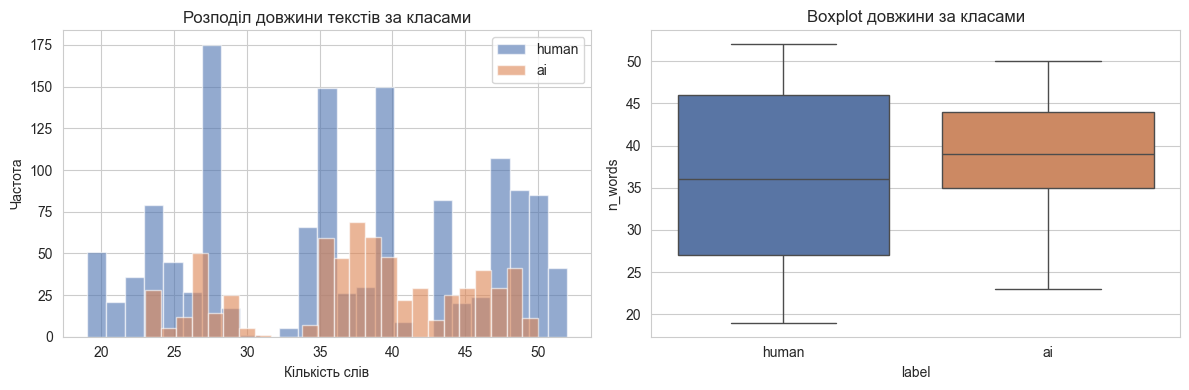

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lab, col in zip(['human', 'ai'], ['#4C72B0', '#DD8452']):
    ax[0].hist(df.loc[df.label == lab, 'n_words'], bins=25, alpha=0.6, label=lab, color=col)
ax[0].set_xlabel('Кількість слів'); ax[0].set_ylabel('Частота'); ax[0].legend()
ax[0].set_title('Розподіл довжини текстів за класами')
sns.boxplot(data=df, x='label', y='n_words', ax=ax[1], palette=['#4C72B0', '#DD8452'])
ax[1].set_title('Boxplot довжини за класами')
plt.tight_layout(); plt.show()

**Опис результату.** Гістограма має **«стовпчастий», багатогорбий вигляд** з порожніми проміжками (наприклад, майже немає текстів довжиною ≈30–33 слова). Це ще одна ознака шаблонності: довжина тексту визначається кількома шаблонами, а не плавним природним розподілом. Людські тексти (синій) охоплюють весь діапазон 19–52 слів і мають кілька високих піків (≈27–28, ≈35 та ≈39–40, а також ≈48–50 слів). ШІ-тексти (помаранчевий) концентруються в діапазоні ≈23–50 слів, переважно ≈35–40. Розподіли **сильно перекриваються**. На boxplot медіана ШІ (39) трохи вища, ніж у людини (36), а «коробка» людського класу (27–46) ширша, ніж у ШІ (35–44). Висновок: **довжина тексту — слабка ознака**, одного лише `word_count` недостатньо, щоб надійно розрізнити класи.

**Висновок (Етап 1).** Датасет містить 2000 текстів, пропусків і порожніх рядків немає, а надто коротких текстів (<10 слів) теж немає (мінімум 19 слів). Класи незбалансовані у співвідношенні 2:1 (1334 людина / 666 ШІ), тому надалі ключовими метриками є macro-F1 та Balanced Accuracy, а не лише Accuracy. Найсерйозніший артефакт — **1034 повні дублікати** `text_content` (51.7%) без суперечливих міток: тексти згенеровані за шаблонами. Розподіли довжини близькі (середнє 38.0 слова для ШІ проти 36.5 для людини), але ШІ-тексти мають вужчий розкид (σ=7.0 проти 9.7): довжина не є надійною ознакою, хоча невелика різниця в розкиді є.

### Обробка дублікатів

Більше половини рядків — точні дублікати (шаблонні тексти). Якби ми залишили їх, ідентичні тексти потрапляли б одночасно і в train, і в test (**витік даних**), а метрики були б штучно завищені. Тому видаляємо дублікати **до** розбиття на train/test. Суперечливих міток немає, тож видалення безпечне.

### 1.5 Видалення дублікатів та кодування мітки

`drop_duplicates('text_content')` залишає лише перше входження кожного унікального тексту, а `reset_index(drop=True)` перенумеровує рядки від 0. Далі створюємо числову мітку **`y`**: `1` — текст згенерований ШІ, `0` — текст людини (більшість sklearn-метрик потребують саме чисел; клас ШІ ми вважаємо «позитивним»).

Дублікати видаляємо саме **зараз**, до розбиття на train/test, щоб одинакові тексти не опинились по обидва боки розбиття.

In [23]:
df = df.drop_duplicates('text_content').reset_index(drop=True)
df['y'] = (df['label'] == 'ai').astype(int)   # 1 = ШІ, 0 = людина
print('Після видалення дублікатів:', df.shape)
print(df['label'].value_counts())
print(f"Частка класу ШІ: {df['y'].mean():.1%}")

Після видалення дублікатів: (966, 11)
label
human    579
ai       387
Name: count, dtype: int64
Частка класу ШІ: 40.1%


**Опис результату.** Залишилось **966 текстів** (579 людських та 387 ШІ). Частка ШІ тепер **40.1%** (замість 33.3% до очищення) — тобто дисбаланс помітно зменшився, але все ще є, тому стратифікація при розбитті та метрики для незбалансованих класів залишаються доречними. Кількість стовпців стала 11, бо додалися `n_words` та `y`.

## Етап 2. Лінгвістична попередня обробка (spaCy)

Використовуємо `en_core_web_sm`. Залишаємо токени, що складаються лише з літер (`is_alpha`) і не є стоп-словами; беремо лему у нижньому регістрі. Для швидкості застосовуємо `nlp.pipe()` із батчами та вимикаємо непотрібні компоненти (parser, ner).

### Пояснення до коду: Лінгвістична обробка

Функція `preprocess` перетворює сирий текст у список «чистих» лем:

1. `spacy.load('en_core_web_sm')` завантажує невелику англійську модель. Компоненти **parser** та **ner** вимкнені (`disable`), бо синтаксичний розбір та розпізнавання іменованих сутностей нам не потрібні, і без них обробка швидша. Для лематизації потрібні компоненти tagger/attribute_ruler, які лишаються.
2. `nlp.pipe(texts, batch_size=64)` обробляє тексти **пакетами по 64**, що набагато швидше, ніж викликати `nlp(text)` для кожного тексту окремо.
3. Із кожного документа лишаємо токен, тільки якщо `t.is_alpha` (лише літери — відкидає цифри, пунктуацію, символи типу «<») **і** `not t.is_stop` (не службове слово типу *the, is, and*), і беремо **лему** (`t.lemma_`, початкова форма слова: *editing → edit*, *people → person*) у **нижньому регістрі**.

Результат записуємо у стовпець `tokens`, рахуємо кількість токенів `n_tokens`, перевіряємо, чи немає порожніх документів, і друкуємо приклад «до / після».

In [24]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

def preprocess(texts, batch_size=64):
    out = []
    for doc in nlp.pipe(texts, batch_size=batch_size):
        out.append([t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop])
    return out

t0 = time.time()
df['tokens'] = preprocess(df['text_content'].tolist())
print(f'Оброблено {len(df)} текстів за {time.time()-t0:.1f} с')
df['n_tokens'] = df['tokens'].str.len()
print('Порожніх після обробки:', (df['n_tokens'] == 0).sum())
print('Середня кількість токенів:', round(df['n_tokens'].mean(), 1))
print('\nПриклад:')
print('ДО :', df.loc[0, 'text_content'][:200])
print('ПІСЛЯ:', df.loc[0, 'tokens'][:25])

Оброблено 966 текстів за 4.1 с
Порожніх після обробки: 0
Середня кількість токенів: 22.0

Приклад:
ДО : can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize
ПІСЛЯ: ['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']


**Опис результату.** 966 текстів оброблено за кілька секунд (≈2–5 с залежно від комп'ютера). **Порожніх документів після обробки немає**, тобто кожен текст має хоча б одне змістовне слово. У середньому лишається **≈22 токени** на документ (для ШІ-текстів ≈23.2, для людських ≈21.2), тобто з ~37 слів очищення прибирає близько 40%. У прикладі речення *«can we talk about gene editing ethics for a sec…»* перетворилося на `['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', …]`: зникли службові слова (*can, we, about, for*), пунктуація, а слова приведені до лем (*editing → edit*, *ethics → ethic*, *missing → miss*). Саме такі списки лем подаються у FastText.

**Висновок (Етап 2).** Після видалення дублікатів лишилося 966 унікальних текстів (579 людина / 387 ШІ, частка ШІ 40.1%). Лематизація та видалення стоп-слів скоротили тексти до ≈22 змістовних токенів на документ; порожніх документів немає. Обробка 966 текстів через `nlp.pipe()` зайняла лише кілька секунд. Слід зауважити, що короткі тексти (≈22 токени) дають зашумлену оцінку TF-IDF на рівні документа.

## Етап 3. Навчання FastText

FastText працює із символьними n-грамами (subword), тому здатний будувати вектор і для слів, яких не було в навчанні (OOV). Модель навчається **без міток** (unsupervised) на лематизованому корпусі, тому використання всього корпусу не призводить до витоку міток.

### Навчання FastText

**Що таке FastText.** Це модель, що навчає вектор для кожного слова, але на відміну від Word2Vec розглядає слово як **набір символьних n-грам** (наприклад, для слова `where` — `<wh, whe, her, ere, re>`). Вектор слова — сума векторів його n-грам. Завдяки цьому:
- схожі за написанням слова (*research, researcher*) мають схожі вектори;
- можна отримати вектор для **слова, якого не було в навчальному корпусі (OOV)** — з його n-грам.

**Параметри за завданням:** `vector_size=100` (розмірність вектора), `window=5` (скільки слів ліворуч/праворуч береться як контекст), `min_count=2` (слова, що зустрічаються менше 2 разів, ігноруються), `sg=1` (архітектура **skip-gram**: за словом передбачаємо контекст), `seed=42` (відтворюваність). Параметр `workers` ми ставимо рівним **1**: за кількох потоків gensim не гарантує однакового результату між запусками.

Після навчання перевіряємо: розмір словника, розмірність, **найближчі слова** до *research* за косинусною подібністю (`most_similar`) та вектор для вигаданого слова `unseenwordxyz` (демонстрація OOV).

In [ ]:
corpus = df['tokens'].tolist()
# workers=1 замість 4 — при кількох потоках gensim не гарантує відтворюваність
# (порядок оновлень вагів недетермінований), і метрики відрізнялись би між запусками.
ft = FastText(sentences=corpus, vector_size=100, window=5, min_count=2,
              sg=1, workers=1, seed=42)
print('Розмір словника FastText:', len(ft.wv.key_to_index))
print('Розмірність вектора:', ft.wv.vector_size)
word = 'research' if 'research' in ft.wv.key_to_index else ft.wv.index_to_key[0]
print(f"Найближчі до '{word}':", ft.wv.most_similar(word, topn=5))
print('OOV-слово (через n-грами):', ft.wv['unseenwordxyz'][:5])

Розмір словника FastText: 508
Розмірність вектора: 100
Найближчі до 'research': [('researcher', 0.8417717814445496), ('mechanism', 0.7822855114936829), ('longitudinal', 0.7428103685379028), ('reveal', 0.7388805150985718), ('assess', 0.722550094127655)]
OOV-слово (через n-грами): [-0.01735479  0.02202844 -0.01531085  0.05949227  0.04209698]


**Опис результату.** Словник FastText — лише **508 слів**: це дуже мало, тобто тексти складаються з обмеженого набору лексики (характерно для шаблонних даних). Розмірність — 100. Найближчі до *research*: *researcher* (≈0.84), *mechanism* (≈0.78), *longitudinal* (≈0.74), *reveal*, *assess* — усе це академічна лексика, тому модель справді вловила смислові зв'язки. Для вигаданого слова `unseenwordxyz` FastText усе одно повернув вектор (числа близькі до нуля, бо слово складається з рідкісних n-грам) — тобто **OOV-слова не ламають агрегацію**, на відміну від Word2Vec, який видав би помилку `KeyError`.

**Висновок (Етап 3).** Словник FastText складається лише з ≈508 слів (при `min_count=2`), що підтверджує шаблонність даних: лексика дуже обмежена. Модель навчила осмислені зв'язки (найближчі до *research*: *researcher*, *mechanism*, *longitudinal*), а для слів поза словником вектор будується з символьних n-грам, тому OOV-слова не ламають агрегацію. Для відтворюваності використано `workers=1` (при `workers=4` результати між запусками трохи відрізнялися через недетермінованість багатопотокового навчання gensim).

## Етап 4. Агрегація: Mean Pooling vs TF-IDF Weighted Mean

Щоб уникнути витоку даних, спочатку розбиваємо індекси на train/test (стратифіковано), а TF-IDF навчаємо **лише на train**; для test використовується IDF з train.

### Підготовка до агрегації: розбиття та TF-IDF

**Навіщо агрегація.** FastText дає вектор кожного слова, а класифікатору потрібен **один вектор на документ**. Є два способи його отримати:
- **Mean Pooling** — просте середнє векторів слів: усі слова рівноправні;
- **TF-IDF Weighted Mean** — зважене середнє, де вага слова = його TF-IDF у документі (рідкісні, «характерні» слова важать більше за часті).

**TF-IDF** = TF (частота слова в документі) × IDF (log від оберненої частки документів, що містять слово). Слово, яке є майже в кожному документі, має малий IDF, а рідкісне слово — великий.

**Порядок дій**:
1. `train_test_split` розбиває **індекси** документів 80/20 зі `stratify=y` (однакова частка ШІ в train і test) та `random_state=42`;
2. `TfidfVectorizer.fit` навчається **тільки на train-документах** (тобто IDF рахується лише за train); на test використовується той самий словник та IDF;
3. `tokenizer=str.split`, `token_pattern=None`, `lowercase=False` — кажемо векторизатору не перетокенізовувати, бо тексти вже лематизовані й розділені пробілами;
4. `doc_scores(i)` повертає словник `{слово: TF-IDF}` для документа `i` — саме він подається у функцію зваженої агрегації.

In [26]:
idx = np.arange(len(df))
idx_tr, idx_te = train_test_split(idx, test_size=0.2, random_state=42, stratify=df['y'])
y = df['y'].values
y_tr, y_te = y[idx_tr], y[idx_te]
print('Train:', len(idx_tr), '| Test:', len(idx_te))
print('Частка ШІ train/test:', y_tr.mean().round(3), y_te.mean().round(3))

# TF-IDF: fit лише на train
docs = [' '.join(t) for t in df['tokens']]
tfidf = TfidfVectorizer(tokenizer=str.split, lowercase=False, token_pattern=None)
tfidf.fit([docs[i] for i in idx_tr])
vocab = tfidf.vocabulary_
X_tfidf = tfidf.transform(docs)           # розріджена матриця (документи × словник)
print('Розмір TF-IDF словника:', len(vocab))

def doc_scores(i):
    """Словник {слово: TF-IDF} для документа i."""
    row = X_tfidf[i]
    inv = tfidf.get_feature_names_out()
    return {inv[j]: v for j, v in zip(row.indices, row.data)}

Train: 772 | Test: 194
Частка ШІ train/test: 0.4 0.402
Розмір TF-IDF словника: 510


**Опис результату.** Train містить **772** документи, test — **194**. Частка ШІ майже однакова в обох вибірках (**0.400** та **0.402**), тобто стратифікація спрацювала. TF-IDF словник має **510 слів** (трохи більше за 508 у FastText, бо FastText відкинув слова з однією появою через `min_count=2`, але вектори для таких слів усе одно можна отримати через n-грами).

### 4.1 Функції агрегації та побудова матриць ознак

- **`mean_pooling(tokens, model)`** — бере вектор `model.wv[t]` для кожного токена документа й повертає їх **середнє** (`np.mean`). Якщо токенів немає — нульовий вектор.
- **`tfidf_weighted_pooling(tokens, model, tfidf_scores)`** — формує масив ваг `w` (TF-IDF кожного токена; невідомі слова отримують вагу 0), **нормує ваги на їх суму** (щоб вони давали 1) і рахує зважене середнє `np.average(..., weights=w)`. Якщо всі ваги нульові — використовуються рівні ваги (запобіжник від ділення на нуль). Порожній документ → нульовий вектор.

Потім для кожного з 966 документів будуємо вектор обома способами й складаємо їх у матриці `X_mean` та `X_wtf` розміру (966 × 100). Для порівняння виводимо **середню L2-норму** (довжину) векторів: вона показує, чи зважування сильно змінює масштаб вектора.

In [27]:
DIM = ft.vector_size

def mean_pooling(tokens, model):
    """Звичайне середнє векторів слів документа."""
    if len(tokens) == 0:
        return np.zeros(model.vector_size)
    return np.mean([model.wv[t] for t in tokens], axis=0)

def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    """Середнє векторів, зважене TF-IDF; ваги нормуються на суму."""
    if len(tokens) == 0:
        return np.zeros(model.vector_size)
    w = np.array([tfidf_scores.get(t, 0.0) for t in tokens], dtype=float)
    if w.sum() == 0:                       # жодне слово не відоме TF-IDF → рівні ваги
        w = np.ones(len(tokens))
    w = w / w.sum()
    return np.average([model.wv[t] for t in tokens], axis=0, weights=w)

X_mean = np.vstack([mean_pooling(t, ft) for t in df['tokens']])
X_wtf = np.vstack([tfidf_weighted_pooling(t, ft, doc_scores(i)) for i, t in enumerate(df['tokens'])])
print('Mean pooling:', X_mean.shape, '| TF-IDF weighted:', X_wtf.shape)
print('Середня L2-норма: mean =', np.linalg.norm(X_mean, axis=1).mean().round(3),
      '| tfidf =', np.linalg.norm(X_wtf, axis=1).mean().round(3))

Mean pooling: (966, 100) | TF-IDF weighted: (966, 100)
Середня L2-норма: mean = 2.401 | tfidf = 2.393


**Опис результату.** Отримали дві матриці **(966, 100)** — по рядку на документ. Середня довжина векторів майже не відрізняється: **2.401** для Mean Pooling та **2.393** для TF-IDF. Це означає, що зважування лише трохи «зсуває» вектори документів, а не змінює їх масштаб. Причина — документи короткі (≈22 слова), слова майже не повторюються, а IDF у малому словнику змінюється помірно, тому ваги в межах документа не дуже різні.

**Висновок (Етап 4).** Обидві агрегації дають вектори розмірності 100. Середня L2-норма майже однакова (≈2.40 проти ≈2.39), тобто TF-IDF-зважування лише незначно зсуває документні вектори. Це очікувано: у коротких документах майже кожне слово зустрічається один раз, тому ваги відрізняються лише через IDF, а IDF у словнику з ≈500 слів змінюється помірно.

## Етап 5. Класифікація та оцінка

Для кожної комбінації «агрегація × класифікатор» навчаємо модель на train і рахуємо метрики на test: macro-F1, Accuracy, Balanced Accuracy, ROC-AUC. Через дисбаланс класів (~60/40) основною метрикою є macro-F1 та Balanced Accuracy.

### 5.1 Навчання класифікаторів та метрики

Функція `get_models()` створює **нові** (неперенавчені) екземпляри трьох класифікаторів із параметрами за завданням:
- **SVM (RBF)** — метод опорних векторів з гаусовим ядром, будує нелінійну межу; `probability=True` дозволяє отримати ймовірності для ROC-AUC;
- **Logistic Regression** — лінійна модель, межа — гіперплощина; `max_iter=1000` дає алгоритму достатньо ітерацій для збіжності;
- **KNN (k=5)** — клас визначається голосуванням 5 найближчих сусідів (метрика — евклідова відстань).

Цикл проходить по двох способах агрегації (`feats`) × трьох моделях і для кожної пари: навчає модель на train, робить передбачення на test, зберігає передбачення (знадобляться для матриць помилок) та рахує **чотири метрики**:
- **F1 (macro)** — середнє F1 по обох класах, враховує дисбаланс;
- **Accuracy** — частка правильних відповідей;
- **Balanced Accuracy** — середнє recall по класах (чесніша за Accuracy при дисбалансі);
- **ROC-AUC** — наскільки добре ймовірності ШІ-класу відокремлюють класи при будь-якому порозі (1.0 — ідеально, 0.5 — випадково).

In [28]:
def get_models():
    return {
        'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=42),
        'LogReg': LogisticRegression(max_iter=1000, random_state=42),
        'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    }
feats = {'Mean Pooling': X_mean, 'TF-IDF Weighted': X_wtf}

rows, preds = [], {}
for fname, X in feats.items():
    Xtr, Xte = X[idx_tr], X[idx_te]
    for mname, m in get_models().items():
        m.fit(Xtr, y_tr)
        yp = m.predict(Xte); ypr = m.predict_proba(Xte)[:, 1]
        preds[(fname, mname)] = yp
        rows.append({'Агрегація': fname, 'Класифікатор': mname,
                     'F1 (macro)': f1_score(y_te, yp, average='macro'),
                     'Accuracy': accuracy_score(y_te, yp),
                     'Balanced Acc': balanced_accuracy_score(y_te, yp),
                     'ROC-AUC': roc_auc_score(y_te, ypr)})
res = pd.DataFrame(rows)
display(res.round(4).style.background_gradient(cmap='Greens', subset=res.columns[2:]))

,Агрегація,Класифікатор,F1 (macro),Accuracy,Balanced Acc,ROC-AUC
0,Mean Pooling,SVM (RBF),0.989300,0.989700,0.991400,0.999600
1,Mean Pooling,LogReg,0.925500,0.927800,0.929200,0.969300
2,Mean Pooling,KNN (k=5),1.000000,1.000000,1.000000,1.000000
3,TF-IDF Weighted,SVM (RBF),0.984000,0.984500,0.987100,1.000000
4,TF-IDF Weighted,LogReg,0.931000,0.933000,0.935600,0.980000
5,TF-IDF Weighted,KNN (k=5),1.000000,1.000000,1.000000,1.000000


**Опис результату (таблиця метрик на test, 194 документи).**

| Агрегація | Класифікатор | F1 macro | Accuracy | Bal. Acc | ROC-AUC |
|---|---|---|---|---|---|
| Mean Pooling | SVM (RBF) | 0.989 | 0.990 | 0.991 | 0.9996 |
| Mean Pooling | LogReg | 0.926 | 0.928 | 0.929 | 0.969 |
| Mean Pooling | KNN | **1.000** | 1.000 | 1.000 | 1.000 |
| TF-IDF Weighted | SVM (RBF) | 0.984 | 0.985 | 0.987 | 1.000 |
| TF-IDF Weighted | LogReg | 0.931 | 0.933 | 0.936 | 0.980 |
| TF-IDF Weighted | KNN | **1.000** | 1.000 | 1.000 | 1.000 |

Зеленим у таблиці підсвічено більші значення. KNN розв'язав задачу ідеально в обох варіантах; SVM майже ідеальний (помилки на 2–3 документах); найслабша — логістична регресія (≈93%). Між Mean і TF-IDF різниці мізерні: для LogReg TF-IDF трохи кращий (+0.005 F1, ROC-AUC 0.969 → 0.980), для SVM — трохи гірший (−0.005). Різниця в 0.005 — це всього ≈1 документ із 194, тому робити висновки лише з цієї таблиці рано (див. перевірки нижче).

### 5.2 Стабільність: крос-валідація та діаграма

Один розподіл train/test може дати випадково щасливий або невдалий результат. Тому для кожної пари «агрегація × модель» ми додатково робимо **5-fold стратифіковану крос-валідацію** на train-вибірці (`StratifiedKFold`, `cross_val_score` зі `scoring='f1_macro'`): дані ділимо на 5 частин, по черзі 4 частини — навчання, 1 — перевірка, і рахуємо **середнє та стандартне відхилення** F1. Мале σ означає стабільний результат.

Нижче стовпчикова діаграма порівнює macro-F1 на test для двох агрегацій.

,Агрегація,Класифікатор,CV F1 mean,CV F1 std
0,Mean Pooling,SVM (RBF),0.9799,0.0120
1,Mean Pooling,LogReg,0.9116,0.0169
2,Mean Pooling,KNN (k=5),1.0000,0.0000
3,TF-IDF Weighted,SVM (RBF),0.9800,0.0133
4,TF-IDF Weighted,LogReg,0.9144,0.0131
5,TF-IDF Weighted,KNN (k=5),1.0000,0.0000


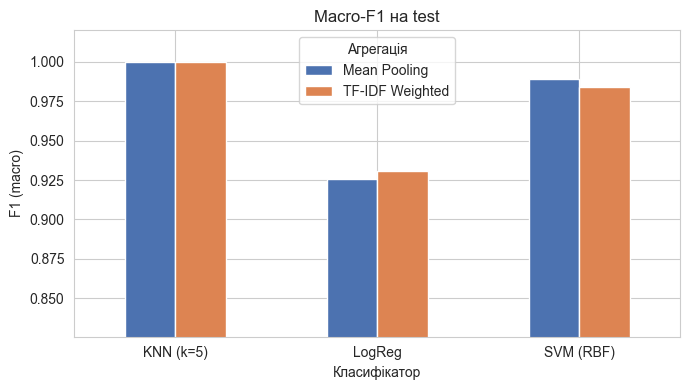

In [29]:
# Стабільність оцінки: 5-fold CV (macro-F1) на train-вибірці
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for fname, X in feats.items():
    for mname, m in get_models().items():
        s = cross_val_score(m, X[idx_tr], y_tr, cv=skf, scoring='f1_macro')
        cv_rows.append({'Агрегація': fname, 'Класифікатор': mname,
                        'CV F1 mean': s.mean(), 'CV F1 std': s.std()})
cv = pd.DataFrame(cv_rows)
display(cv.round(4))

piv = res.pivot(index='Класифікатор', columns='Агрегація', values='F1 (macro)')
piv.plot.bar(rot=0, figsize=(7, 4), color=['#4C72B0', '#DD8452'])
plt.ylabel('F1 (macro)'); plt.title('Macro-F1 на test'); plt.ylim(max(0, piv.values.min() - 0.1), 1.02)
plt.tight_layout(); plt.show()

**Опис результату.** *Таблиця CV:* KNN має F1 = 1.000 (σ = 0) в усіх фолдах; SVM ≈ 0.980 (σ ≈ 0.012–0.013) для обох агрегацій; LogReg ≈ 0.91 (Mean, σ ≈ 0.017) проти ≈ 0.914 (TF-IDF, σ ≈ 0.013). Різниця між агрегаціями (≈0.003 у LogReg, ≈0.000 у SVM) **менша за розкид між фолдами**, тобто в межах шуму.

*Діаграма:* стовпчики синього (Mean) та помаранчевого (TF-IDF) кольорів майже однакової висоти для кожної моделі; KNN — найвищий («стеля» 1.0), SVM — трохи нижче, LogReg — помітно нижче. Вісь Y починається не з нуля, тому різниці візуально виглядають більшими, ніж вони є.

### 5.3 Додаткові перевірки надійності

Метрики близькі до 1.0 викликають запитання, тому проводимо три перевірки:

**(а) Майже-дублікати.** Для кожного тестового документа знаходимо максимальну **косинусну подібність** до документів train (`normalize(X_te) @ normalize(X_tr).T` — скалярні добутки нормованих векторів = косинус). Якщо вона ≈1, то в train є практично такий самий документ, і модель могла його «запам'ятати».

**(б) Bootstrap-перевірка різниці агрегацій.** 1000 разів випадково перевибираємо (з поверненням) тестові документи та рахуємо ΔF1 = F1(TF-IDF) − F1(Mean). Інтервал між 2.5-м та 97.5-м перцентилями — **95% довірчий інтервал**. Якщо він містить 0, різниця статистично незначуща.

**(в) GroupKFold за темою.** Документи однієї теми (`topic_hint`) завжди потрапляють в одну частину розбиття, тож під час перевірки модель бачить теми, яких не було в навчанні. Це жорсткіше за звичайний розподіл.

In [30]:
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import normalize
# (а) майже-дублікати: макс. косинусна подібність test→train
for fname, X in feats.items():
    S = normalize(X[idx_te]) @ normalize(X[idx_tr]).T
    mx = S.max(1)
    print(f'{fname}: медіана max-cos = {np.median(mx):.4f}; частка test з cos>0.99 до train: {(mx>0.99).mean():.1%}')

# (б) bootstrap різниці F1(TF-IDF) - F1(Mean) на test
rng = np.random.RandomState(42)
boot_rows = []
for mname in get_models():
    a, b = preds[('Mean Pooling', mname)], preds[('TF-IDF Weighted', mname)]
    diffs = []
    for _ in range(1000):
        j = rng.randint(0, len(y_te), len(y_te))
        diffs.append(f1_score(y_te[j], b[j], average='macro') - f1_score(y_te[j], a[j], average='macro'))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    boot_rows.append({'Класифікатор': mname, 'ΔF1 (TFIDF−Mean)': np.mean(diffs), '95% CI low': lo, '95% CI high': hi})
display(pd.DataFrame(boot_rows).round(4))

# (в) GroupKFold за темою
groups = df['topic_hint'].values
gkf = GroupKFold(n_splits=5)
g_rows = []
for fname, X in feats.items():
    for mname, m in get_models().items():
        sc = cross_val_score(m, X, y, cv=gkf, groups=groups, scoring='f1_macro')
        g_rows.append({'Агрегація': fname, 'Класифікатор': mname, 'F1 (GroupKFold) mean': sc.mean(), 'std': sc.std()})
display(pd.DataFrame(g_rows).round(4))

Mean Pooling: медіана max-cos = 0.9991; частка test з cos>0.99 до train: 94.3%
TF-IDF Weighted: медіана max-cos = 0.9990; частка test з cos>0.99 до train: 94.8%


,Класифікатор,ΔF1 (TFIDF−Mean),95% CI low,95% CI high
0,SVM (RBF),-0.0054,-0.017,0.0000
1,LogReg,0.0051,0.000,0.0169
2,KNN (k=5),0.0000,0.000,0.0000


,Агрегація,Класифікатор,F1 (GroupKFold) mean,std
0,Mean Pooling,SVM (RBF),0.9893,0.0057
1,Mean Pooling,LogReg,0.9211,0.0082
2,Mean Pooling,KNN (k=5),1.0000,0.0000
3,TF-IDF Weighted,SVM (RBF),0.9850,0.0039
4,TF-IDF Weighted,LogReg,0.9275,0.0111
5,TF-IDF Weighted,KNN (k=5),1.0000,0.0000


**Опис результату.**

**(а)** Медіана максимальної косинусної подібності test→train дорівнює **≈0.999** для обох агрегацій, а у **≈94–95%** тестових документів у train є сусід із подібністю >0.99. Тобто тестові тексти — це майже копії навчальних (однаковий шаблон, лише інша тема/слово), і високі метрики значною мірою пояснюються цим.

**(б)** Bootstrap: SVM ΔF1 ≈ −0.005, 95% ДІ [−0.017; 0.000]; LogReg ΔF1 ≈ +0.005, ДІ [0.000; 0.017]; KNN ΔF1 = 0. Усі інтервали **торкаються нуля**, отже різниця між агрегаціями **статистично незначуща**.

**(в)** GroupKFold за темою дає практично ті самі значення: KNN 1.000; SVM ≈0.989 (Mean) / ≈0.985 (TF-IDF); LogReg ≈0.92 / ≈0.93. Метрики не просіли, тож модель розрізняє класи за **стилем шаблону**, а не за темою.

**Висновок (Етап 5).** Результати на test (194 документи): **KNN — 1.000 за всіма метриками для обох агрегацій; SVM (RBF) — macro-F1 0.989 (Mean) і 0.984 (TF-IDF), ROC-AUC ≈1.0; Logistic Regression — 0.926 (Mean) і 0.931 (TF-IDF), ROC-AUC 0.969 → 0.980.** Різниця між агрегаціями мізерна: для LogReg TF-IDF дає +0.005 macro-F1 (≈1 документ із 194), для SVM −0.005 (≈1 документ). Bootstrap-інтервали ΔF1 для SVM [−0.017; 0.000] та LogReg [0.000; 0.017] торкаються нуля, тобто **статистично значущої переваги жодної з агрегацій немає**. Лише ROC-AUC для LogReg зріс помітніше (0.969 → 0.980), що узгоджується з гіпотезою про трохи кращу лінійну роздільність. Дуже високі метрики пояснюються структурою датасету: ≈94% тестових документів мають у train сусіда з косинусною подібністю >0.99 (майже-дублікати з шаблону, відрізняються лише темою). Тому KNN, який по суті «запам'ятовує» шаблони, ідеальний. Перевірка за темами (GroupKFold за `topic_hint`) дає практично ті самі значення (SVM ≈0.989/≈0.985, LogReg ≈0.92/≈0.93, KNN 1.000), отже поділ за темою не прибирає шаблонність: класи розрізняються стилем шаблону, а не темою.

## Етап 6. Візуалізація

### 6.1 Проєкція t-SNE
Окремо для Mean Pooling та TF-IDF Weighted Mean (усі документи, кольором — клас). Додатково рахуємо числові міри геометрії: silhouette у вихідному 100-вимірному просторі та відношення міжкласової відстані центроїдів до середньої внутрішньокласової дисперсії.

### Пояснення до коду: Візуалізація геометрії простору

**t-SNE** — нелінійний метод зниження розмірності, який проєктує 100-вимірні вектори на площину так, щоб **близькі точки лишались близькими** (зберігає локальну структуру). Параметри: `perplexity=30` (орієнтовна кількість «сусідів» для кожної точки), `init='pca'` (стабільніший початок), `random_state=42`. Зверніть увагу: відстані *між* далекими групами на t-SNE інтерпретувати не можна, лише факт наявності компактних груп.

Малюємо **окремий графік для кожної агрегації**: точки — документи, колір — клас (синій — людина, помаранчевий — ШІ).

Крім картинки, рахуємо числа:
- **Silhouette** (від −1 до 1): наскільки точка ближча до свого класу, ніж до чужого; рахуємо у вихідному 100D-просторі та в 2D;
- **Відношення Фішера** = (відстань між центрами класів)² / (сума внутрішньокласових дисперсій): чим більше, тим краще класи розділяються.

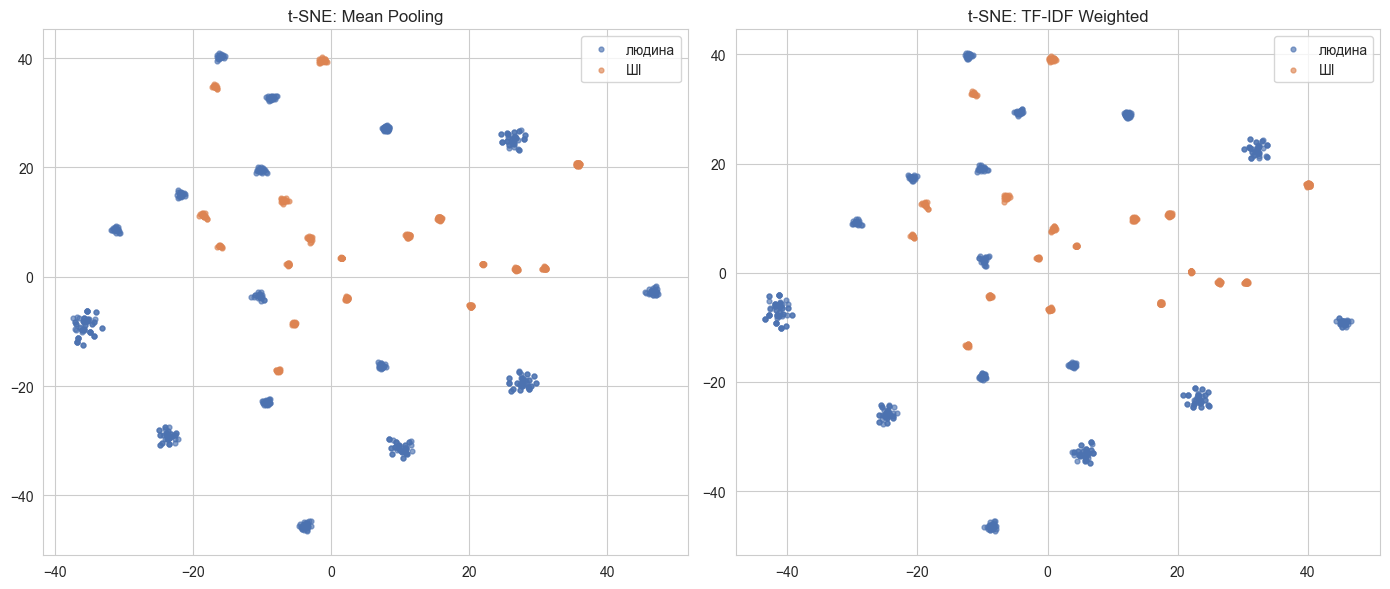

,Silhouette (100D),Silhouette (t-SNE 2D),Fisher ratio (100D)
Mean Pooling,0.0436,0.0709,0.0864
TF-IDF Weighted,0.0450,0.0724,0.0896


In [31]:
def tsne2d(X):
    return TSNE(n_components=2, perplexity=30, random_state=42, init='pca').fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
emb2d = {}
for ax, (fname, X) in zip(axes, feats.items()):
    Z = tsne2d(X); emb2d[fname] = Z
    for lab, col, name in [(0, '#4C72B0', 'людина'), (1, '#DD8452', 'ШІ')]:
        ax.scatter(Z[y == lab, 0], Z[y == lab, 1], s=12, alpha=0.65, c=col, label=name)
    ax.set_title(f't-SNE: {fname}'); ax.legend()
plt.tight_layout(); plt.show()

def fisher_ratio(X, y):
    c0, c1 = X[y == 0].mean(0), X[y == 1].mean(0)
    within = (X[y == 0].var(0).sum() + X[y == 1].var(0).sum())
    return np.sum((c0 - c1) ** 2) / within

geo = pd.DataFrame({
    fname: {'Silhouette (100D)': silhouette_score(X, y),
            'Silhouette (t-SNE 2D)': silhouette_score(emb2d[fname], y),
            'Fisher ratio (100D)': fisher_ratio(X, y)}
    for fname, X in feats.items()}).T
display(geo.round(4))

**Опис результату.** *Графіки:* на обох проєкціях точки утворюють **десятки дуже щільних компактних «острівців»**; кожен острівець — це набір текстів з одного шаблону. Помаранчеві (ШІ) та сині (людина) острівці лежать окремо й майже ніде не змішуються. Одна важлива деталь: клас — це не один великий кластер, а **багато окремих груп**, розкиданих по всій площині. Для лінійної моделі це проблема, бо одна пряма не може відокремити всі такі острівці. Для обох агрегацій картина майже ідентична: різниця лише в дрібних деталях (положення та розкид окремих груп), чіткої візуальної переваги жодної з агрегацій немає.

*Таблиця:* silhouette у 100D — 0.0436 (Mean) та 0.0450 (TF-IDF); відношення Фішера — 0.0864 та 0.0896 (+3.7%); silhouette у 2D — ≈0.071 та ≈0.072 (різниця ≈0.001–0.002 лежить у межах випадковості t-SNE і між запусками може змінювати знак). Значення silhouette близькі до нуля, бо клас складається з багатьох далеких груп (середня відстань до «свого» класу велика), тому цей показник тут занижений; важливіший **напрямок різниці** — TF-IDF трохи краще у 100D, а у 2D різниця настільки мала, що її не варто інтерпретувати.

**Висновок (t-SNE).** На обох проєкціях дані утворюють **десятки дуже щільних компактних кластерів** (по одному на шаблон), причому кластери ШІ та людини майже не змішуються. Це підтверджує високі метрики KNN та SVM. Різниця між агрегаціями візуально мінімальна. Числові міри: silhouette у 100D 0.0436 (Mean) проти 0.0450 (TF-IDF), відношення Фішера 0.0864 проти 0.0896 (+3.7%), silhouette у 2D практично однаковий (≈0.071 проти ≈0.072, різниця в межах випадковості t-SNE). Низькі абсолютні значення silhouette пояснюються тим, що кожен клас складається з багатьох віддалених кластерів-шаблонів (клас не є одним «згустком»), тому глобальна міра compact-ness низька при локально ідеальній роздільності. TF-IDF-зважування дає лише невелике покращення глобальної геометрії у вихідному 100D-просторі.

### 6.2 Матриці помилок

**Матриця помилок** (confusion matrix) — таблиця 2×2: рядки — справжній клас, стовпці — передбачений. Діагональ — правильні відповіді; поза діагоналлю — помилки: *людина → ШІ* (хибне спрацювання) та *ШІ → людина* (пропуск). Клітинка рахує `confusion_matrix(y_te, передбачення)` для кожної з 6 комбінацій та малює їх у сітці 2×3 (верхній ряд — Mean Pooling, нижній — TF-IDF Weighted; стовпці — SVM, LogReg, KNN). У тесті 116 людських та 78 ШІ-документів.

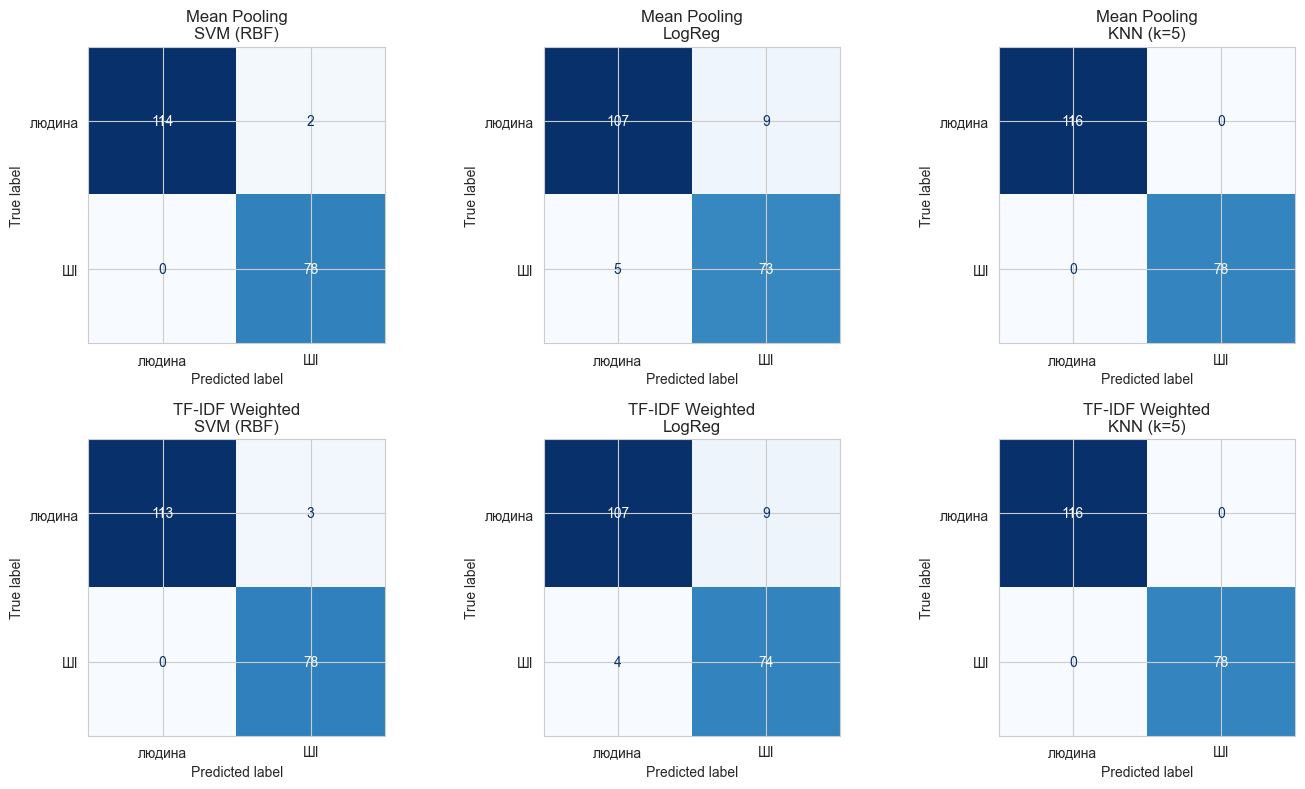

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for r, fname in enumerate(feats):
    for c, mname in enumerate(get_models()):
        cm = confusion_matrix(y_te, preds[(fname, mname)])
        ConfusionMatrixDisplay(cm, display_labels=['людина', 'ШІ']).plot(ax=axes[r, c], colorbar=False, cmap='Blues')
        axes[r, c].set_title(f'{fname}\n{mname}')
plt.tight_layout(); plt.show()

**Опис результату** (формат [[людина→людина, людина→ШІ], [ШІ→людина, ШІ→ШІ]]):

- **KNN** (обидві агрегації): `[[116, 0], [0, 78]]` — жодної помилки.
- **SVM, Mean:** `[[114, 2], [0, 78]]` — 2 помилки, обидві *людина → ШІ*; усі 78 ШІ-текстів знайдено. **SVM, TF-IDF:** `[[113, 3], [0, 78]]` — 3 помилки такого ж типу.
- **LogReg, Mean:** `[[107, 9], [5, 73]]` — 14 помилок (9 хибних спрацювань та 5 пропусків). **LogReg, TF-IDF:** `[[107, 9], [4, 74]]` — 13 помилок; тобто TF-IDF «врятував» один ШІ-текст, який пропустив Mean Pooling.

Отже, SVM схильний помилково називати деякі людські тексти ШІ-подібними (але не навпаки), а лінійна регресія помиляється в обох напрямках.

**Висновок (матриці помилок).** KNN не робить жодної помилки в обох конфігураціях. SVM помиляється на 2–3 документах з 194, і всі помилки — це людські тексти, які модель вважає ШІ (пропусків ШІ немає). Logistic Regression робить найбільше помилок (14 для Mean і 13 для TF-IDF): лінійна межа не здатна повністю розділити багато окремих кластерів шаблонів; помилки йдуть в обидва боки (9 хибних спрацювань і 4–5 пропусків ШІ), що узгоджується з Balanced Accuracy ≈ Accuracy. TF-IDF-зважування «виправило» один пропущений ШІ-текст у LogReg.

## Етап 7. Лінгвістична інтерпретація: які слова та n-грами мають найвищий TF-IDF у класі ШІ

Для кожного слова (та біграми) рахуємо середній TF-IDF по документах класу ШІ та людини на train-вибірці; різниця показує слова-маркери.

### Пояснення до коду: Які слова є маркерами ШІ-тексту

Щоб відповісти на лінгвістичне питання, шукаємо слова та біграми (пари сусідніх слів), які **найсильніше відрізняють** класи за TF-IDF:

1. функція `top_terms(ngram, min_df, k)` навчає окремий `TfidfVectorizer` на train-документах (щоб не використовувати тест); `ngram_range=(1,1)` — окремі слова, `(2,2)` — біграми; `min_df=5` відкидає слова, що трапляються менше ніж у 5 документах (випадковий шум);
2. рахує **середній TF-IDF** кожного терміна окремо в документах ШІ (`tfidf_AI`) та людини (`tfidf_human`);
3. сортує за різницею `diff = tfidf_AI − tfidf_human` — найбільші додатні значення — маркери ШІ, найбільші за модулем від'ємні — маркери людини.

Виводимо 4 таблиці (слова/біграми × ШІ/людина), по 15 рядків у кожній.

In [33]:
def top_terms(ngram, min_df=5, k=15):
    v = TfidfVectorizer(tokenizer=str.split, lowercase=False, token_pattern=None,
                        ngram_range=ngram, min_df=min_df)
    tr_docs = [docs[i] for i in idx_tr]
    M = v.fit_transform(tr_docs)
    names = v.get_feature_names_out()
    m_ai = np.asarray(M[y_tr == 1].mean(0)).ravel()
    m_hu = np.asarray(M[y_tr == 0].mean(0)).ravel()
    d = pd.DataFrame({'term': names, 'tfidf_AI': m_ai, 'tfidf_human': m_hu, 'diff': m_ai - m_hu})
    return d.sort_values('diff', ascending=False).head(k), d.sort_values('diff').head(k)

ai_uni, hu_uni = top_terms((1, 1))
ai_bi, hu_bi = top_terms((2, 2))
print('=== Уніграми: найхарактерніші для ШІ ==='); display(ai_uni.round(4))
print('=== Уніграми: найхарактерніші для людини ==='); display(hu_uni.round(4))
print('=== Біграми: найхарактерніші для ШІ ==='); display(ai_bi.round(4))
print('=== Біграми: найхарактерніші для людини ==='); display(hu_bi.round(4))

=== Уніграми: найхарактерніші для ШІ ===


,term,tfidf_AI,tfidf_human,diff
429,solution,0.0311,0.0,0.0311
464,think,0.0307,0.0,0.0307
157,expert,0.0282,0.0,0.0282
481,underscore,0.0276,0.0,0.0276
435,stakeholder,0.0275,0.0,0.0275
119,development,0.0268,0.0,0.0268
365,recommendation,0.0264,0.0,0.0264
332,potential,0.0261,0.0,0.0261
364,recommend,0.0260,0.0,0.0260
346,progress,0.0260,0.0,0.0260


=== Уніграми: найхарактерніші для людини ===


,term,tfidf_AI,tfidf_human,diff
25,argue,0.0000,0.0357,-0.0357
304,official,0.0068,0.0386,-0.0319
472,today,0.0000,0.0288,-0.0288
405,say,0.0000,0.0283,-0.0283
482,understand,0.0000,0.0278,-0.0278
457,tell,0.0000,0.0276,-0.0276
234,investigation,0.0000,0.0272,-0.0272
182,get,0.0000,0.0268,-0.0268
128,divide,0.0041,0.0301,-0.0261
254,line,0.0000,0.0258,-0.0258


=== Біграми: найхарактерніші для ШІ ===


,term,tfidf_AI,tfidf_human,diff
3,acknowledge complexity,0.0220,0.0,0.0220
466,reduce talk,0.0220,0.0,0.0220
202,exhausting acknowledge,0.0220,0.0,0.0220
100,complexity instead,0.0220,0.0,0.0220
285,instead reduce,0.0220,0.0,0.0220
572,talk point,0.0220,0.0,0.0220
582,thing move,0.0209,0.0,0.0209
215,fascinating quickly,0.0209,0.0,0.0209
587,thoughtfully thought,0.0209,0.0,0.0209
450,quickly thing,0.0209,0.0,0.0209


=== Біграми: найхарактерніші для людини ===


,term,tfidf_AI,tfidf_human,diff
22,announcement come,0.0,0.0264,-0.0264
32,argue premature,0.0,0.0264,-0.0264
564,supporter long,0.0,0.0264,-0.0264
542,speculation critic,0.0,0.0264,-0.0264
127,critic argue,0.0,0.0264,-0.0264
430,premature supporter,0.0,0.0264,-0.0264
500,response divide,0.0,0.0264,-0.0264
92,come week,0.0,0.0264,-0.0264
427,predictable line,0.0,0.0264,-0.0264
444,public response,0.0,0.0264,-0.0264


**Опис результату.** *Слова-маркери ШІ:* **solution, think, expert, underscore, stakeholder, development, recommendation, potential, address, engage** — формальна, «консультативна» лексика. *Слова-маркери людини:* **argue, official, today, say, tell, investigation, speculation, critic** — новинна та розмовна лексика. *Біграми ШІ:* **acknowledge complexity, potential approach, approach thoughtfully, complexity instead, fascinating quickly**; *біграми людини:* **official confirm, long overdue, critic argue, week speculation, come week**. У більшості термінів один із класів має TF-IDF = 0 (слово взагалі не зустрічається в іншому класі), що типово для шаблонних даних.

### Візуалізація топ-слів

Горизонтальні стовпчикові діаграми показують **абсолютну різницю** середнього TF-IDF (|ΔTF-IDF|) для 15 слів: ліворуч — найхарактерніші для класу ШІ (помаранчеві), праворуч — для класу «людина» (сині). Довший стовпчик = слово сильніше відрізняє клас.

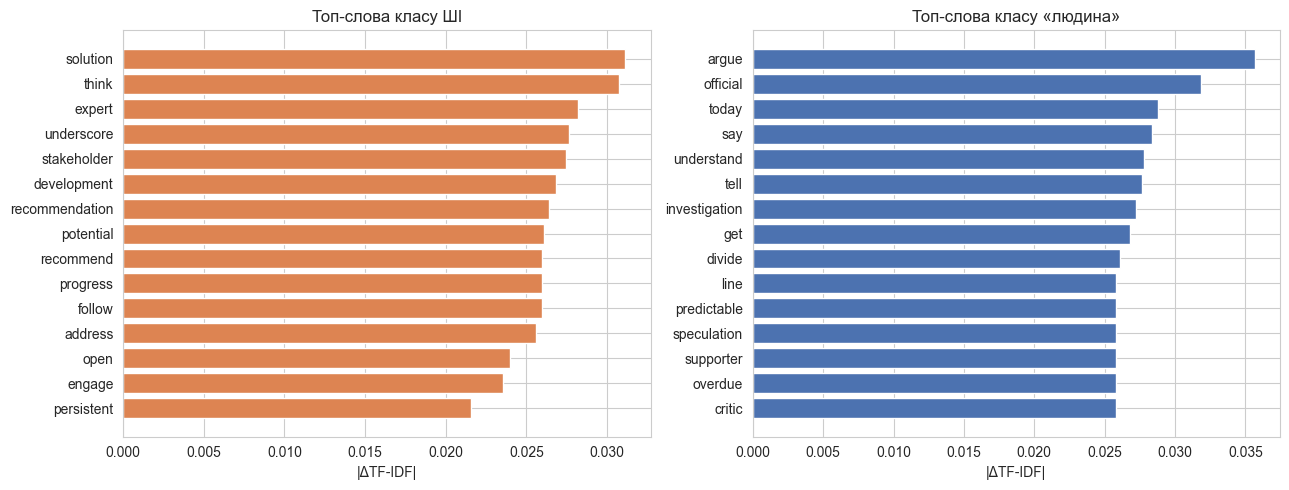

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, d, t, col in [(ax[0], ai_uni.iloc[::-1], 'Топ-слова класу ШІ', '#DD8452'),
                     (ax[1], hu_uni.iloc[::-1], 'Топ-слова класу «людина»', '#4C72B0')]:
    a.barh(d['term'], d['diff'].abs(), color=col); a.set_title(t); a.set_xlabel('|ΔTF-IDF|')
plt.tight_layout(); plt.show()

**Опис результату.** На лівому графіку найдовші стовпчики мають *solution* та *think* (≈0.031), далі *expert*, *underscore*, *stakeholder* (≈0.028). На правому — *argue* (≈0.036), *official* (≈0.032), *today*, *say* (≈0.029). Стовпчики спадають плавно, тобто немає одного «суперслова»: клас визначається **набором** характерних слів, а не окремим маркером. Це якраз і пояснює, чому усереднення векторів багатьох слів працює для задачі.

**Висновок (лінгвістична інтерпретація).** Слова з найвищою перевагою TF-IDF у класі ШІ: *solution, think, expert, underscore, stakeholder, development, recommendation, potential, address, engage, persistent*; біграми: *acknowledge complexity, potential approach, approach thoughtfully, complexity instead, fascinating quickly*. Це типова «ввічлива, нейтрально-корпоративна» лексика та хеджовані формулювання (*acknowledge complexity*, *thoughtfully*, *stakeholder*), що відповідає відомим стилістичним ознакам LLM-текстів. Для людських текстів характерні *argue, official, today, say, tell, investigation, speculation, critic*, біграми *official confirm, long overdue, critic argue* — мова новин, суперечок, розмовні дієслова (*say, tell, get*). **Застереження:** більшість цих термінів у протилежному класі мають TF-IDF = 0, тобто вони є артефактами шаблонів синтетичного датасету, а не універсальними маркерами ШІ; на реальних текстах такий перелік був би значно «розмитішим».

## Відповіді на дослідницькі питання

### Питання 1. Як TF-IDF-зважування змінює геометрію простору порівняно з Mean Pooling і чому це може (не) покращувати лінійну роздільність?

Mean Pooling дає центроїд векторів слів, у якому **часті слова мають такий самий внесок, як і рідкісні**. TF-IDF-зважування зміщує центроїд у бік рідкісних (за документною частотою) слів, тобто в бік напрямків, специфічних для класу, і зменшує внесок «фонових» слів, спільних для обох класів. Теоретично це збільшує відстань між центроїдами класів відносно внутрішньокласового розкиду, а отже поліпшує лінійну роздільність. У нашому експерименті ефект є, але **малий**: відношення Фішера зросло з 0.0864 до 0.0896 (+3.7%), silhouette у 100D з 0.0436 до 0.0450, ROC-AUC для LogReg з 0.969 до 0.980, а macro-F1 змінився лише на ≈0.005. Причини слабкого ефекту: (1) документи дуже короткі (≈22 токени), майже всі слова входять один раз, тому ваги відрізняються тільки через IDF; (2) словник маленький (≈510 слів) і IDF змінюється помірно; (3) FastText-вектори слів уже кодують розподільну семантику, а усереднення зглажує відмінності. Отже, гіпотеза підтверджується **якісно (напрямок ефекту), але не статистично значуще**.

### Питання 2. Який класифікатор найкращий для кожної агрегації і як це пов'язано з лінійною/нелінійною роздільністю?

Для **обох** агрегацій найкращий KNN (macro-F1 = 1.000), далі SVM (RBF) (0.989 / 0.984), найгірший — Logistic Regression (0.926 / 0.931). Лінійна модель найслабша, бо клас «ШІ» (як і «людина») складається з багатьох окремих кластерів-шаблонів, розташованих у різних місцях простору: їх не можна відокремити однією гіперплощиною (це нелінійно роздільна, мультимодальна задача). SVM з RBF-ядром будує локальні нелінійні межі й майже ідеально це описує. KNN, будучи суто локальним методом, ідеально працює, бо кожен тестовий документ має у train майже ідентичного сусіда того ж класу (≈94% мають cos>0.99). Нелінійні методи виграють в обох агрегаціях, а TF-IDF помітніше допомагає саме лінійній моделі (LogReg), що й узгоджується з тим, що вона — єдина обмежена лінійною роздільністю.

### Питання 3. Чому KNN може деградувати при переході Mean → TF-IDF?

Теоретично можливі дві причини. (1) **Прокляття розмірності**: у 100-вимірному просторі відстані між точками концентруються (контраст між «найближчим» та «найдальшим» сусідом зменшується), а TF-IDF-зважування, зсуваючи вектори в бік рідкісних слів, може додатково розширювати розкид і зменшувати контраст. (2) **Властивості метрики**: евклідова відстань чутлива до масштабу й норми; зважене середнє змінює норми векторів неоднорідно (документи з рідкісними словами «відлітають» далі), і ранжування сусідів стає менш стабільним. У нашому експерименті **деградації KNN не спостерігається** (1.000 → 1.000): норми векторів майже не змінилися (2.40 → 2.39), а дані мають кластерну шаблонну структуру, в якій найближчі сусіди майже ідентичні (cos ≈ 0.999), тому ефекти розмірності та метрики не проявляються. На реальних, різноманітніших текстах (довші документи, більший словник) деградація була б імовірнішою.

### Питання 4. Лінгвістична інтерпретація: які слова та n-грами мають найвищий TF-IDF у класі ШІ і чи можуть вони бути маркерами?

У класі ШІ найвищі TF-IDF мають *solution, think, expert, underscore, stakeholder, development, recommendation, potential, address*, а також біграми *acknowledge complexity, potential approach, approach thoughtfully, complexity instead*. Це лексика формального, збалансованого, «консультативного» тону з хеджуванням і абстрактними іменниками (*stakeholder, development, potential*), яка добре узгоджується зі стилем LLM (ввічливість, узагальнення, заклики до обговорення). Люди натомість частіше використовують конкретну журналістську/розмовну лексику (*official, investigation, say, tell, today, argue, critic*). Такі слова **можуть слугувати маркерами** у межах цього датасету (багато з них зустрічаються лише в ШІ-тексті), проте варто враховувати, що датасет синтетичний і шаблонний: ці терміни відображають шаблони генерації, а не гарантовані властивості реальних LLM. У реальних даних один лише набір слів буде слабшим ознаком, а доведеться використовувати комбінації ознак.

### Питання 5. Геометричний аналіз t-SNE: чи утворюються компактні кластери і яка агрегація краще кластеризує?

На t-SNE обидві агрегації дають **компактні, добре відокремлені кластери** (≈20 щільних груп на клас), де кластери ШІ та людини практично не перетинаються. Це відповідає майже ідеальним метрикам нелінійних моделей. Різниця між агрегаціями візуально мала: візуально проєкції майже не відрізняються, а числові показники у вихідному просторі (silhouette 100D 0.0450 проти 0.0436; відношення Фішера 0.0896 проти 0.0864) трохи кращі для TF-IDF, тоді як silhouette у 2D практично однаковий (≈0.071 проти ≈0.072, різниця в межах випадковості t-SNE). Тому TF-IDF Weighted Mean кластеризує **трохи краще у вихідному просторі**, але ця перевага невелика й не змінює якісної картини. Загалом клас не є одним зв'язним кластером, а складається з багатьох шаблонних підкластерів, що пояснює низькі абсолютні значення silhouette і слабкість лінійної моделі.

## Загальний висновок

У роботі побудовано повний пайплайн детекції текстів ШІ: spaCy-обробка → FastText (subword) → два способи агрегації (Mean Pooling, TF-IDF Weighted Mean) → SVM (RBF), Logistic Regression, KNN → метрики, t-SNE, матриці помилок і лінгвістичний аналіз.

**Головні результати:**
- Для коректної оцінки з 2000 текстів видалено 1034 дублікати (лишилося 966), інакше був би прямий витік між train і test.
- Усі моделі показали високу якість: KNN — 1.000, SVM (RBF) — macro-F1 ≈0.98–0.99, Logistic Regression — ≈0.93.
- **Гіпотеза про перевагу TF-IDF підтверджена лише слабко:** напрямок ефекту збігається (краща геометрія: відношення Фішера +3.7%; для LogReg ROC-AUC 0.969 → 0.980, macro-F1 +0.005), але різниця статистично незначуща (bootstrap CI торкаються нуля), а для SVM F1 навіть трохи нижчий (−0.005).
- Нелінійні моделі суттєво кращі за лінійну, оскільки класи складаються з багатьох кластерів-шаблонів.
- Лінгвістичний аналіз виділив типові ШІ-маркери (*acknowledge complexity*, *stakeholder*, *recommendation*, *thoughtfully*) та людські (*official confirm*, *critic argue*, *investigation*).

**Обмеження:** датасет синтетичний, шаблонний, тексти короткі, а словник дуже малий; високі метрики значною мірою відображають «запам'ятовування» шаблонів (≈94% тестових текстів мають майже-дублікат у train), тому на реальних текстах слід очікувати нижчі показники і, ймовірно, більшу перевагу TF-IDF-зважування для довших документів. Також FastText навчався без міток на всьому корпусі (unsupervised), а TF-IDF — лише на train, що виключає витік міток.